# Logistic Regression with Sentence Transformer Embeddings

Train and evaluate a logistic regression classifier using pretrained sentence embeddings.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

## Load Data and Embeddings

Load the train, validation, and test datasets along with their saved sentence embeddings.

In [2]:
PROJECT_ROOT = Path("../..")

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

MODELS_DIR = PROJECT_ROOT / "models"
EMBEDDINGS_MODEL_DIR = MODELS_DIR / "embeddings"

In [3]:
train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
validation_df = pd.read_csv(PROCESSED_DIR / "validation.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

X_train = np.load(
    EMBEDDINGS_MODEL_DIR / "train_embeddings.npy"
)

X_validation = np.load(
    EMBEDDINGS_MODEL_DIR / "validation_embeddings.npy"
)

X_test = np.load(
    EMBEDDINGS_MODEL_DIR / "test_embeddings.npy"
)

y_train = train_df["target"].to_numpy()
y_validation = validation_df["target"].to_numpy()
y_test = test_df["target"].to_numpy()

In [4]:
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)

assert len(X_train) == len(y_train)
assert len(X_validation) == len(y_validation)
assert len(X_test) == len(y_test)

Train: (58823, 384) (58823,)
Validation: (12611, 384) (12611,)
Test: (12632, 384) (12632,)


## Train Logistic Regression

Train a logistic regression classifier using the sentence embeddings and balanced class weights.

In [5]:
model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model.fit(
    X_train,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

## Evaluate on Validation Data

Evaluate the embedding-based logistic regression model on the validation set.

In [6]:
val_preds = model.predict(X_validation)
val_probs = model.predict_proba(X_validation)[:, 1]

print(
    "Validation Accuracy:",
    accuracy_score(y_validation, val_preds)
)

print(
    "Validation Macro Precision:",
    precision_score(
        y_validation,
        val_preds,
        average="macro"
    )
)

print(
    "Validation Macro Recall:",
    recall_score(
        y_validation,
        val_preds,
        average="macro"
    )
)

print(
    "Validation Macro F1:",
    f1_score(
        y_validation,
        val_preds,
        average="macro"
    )
)

print(
    "Validation ROC-AUC:",
    roc_auc_score(
        y_validation,
        val_probs
    )
)

Validation Accuracy: 0.8548885893267782
Validation Macro Precision: 0.8305149974243373
Validation Macro Recall: 0.8563491293587058
Validation Macro F1: 0.8400507083111896
Validation ROC-AUC: 0.9317619612549464


Validation Confusion Matrix:
[[7311 1267]
 [ 563 3470]]


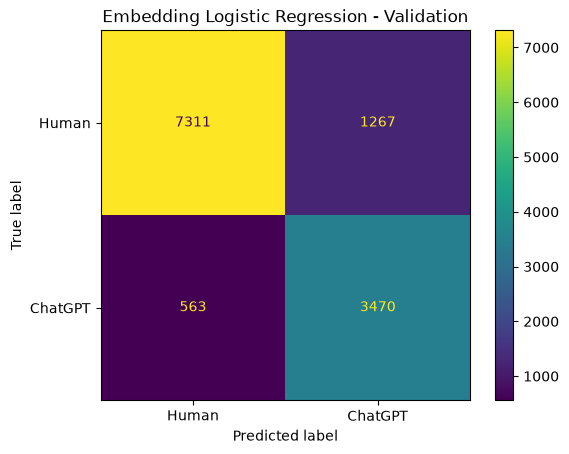

In [7]:
val_cm = confusion_matrix(
    y_validation,
    val_preds
)

print("Validation Confusion Matrix:")
print(val_cm)

ConfusionMatrixDisplay(
    confusion_matrix=val_cm,
    display_labels=["Human", "ChatGPT"]
).plot()

plt.title(
    "Embedding Logistic Regression - Validation"
)

plt.show()

## Evaluate on Test Data

Evaluate the final model on the held-out test set using the same performance metrics.

In [10]:
test_preds = model.predict(X_test)
test_probs = model.predict_proba(X_test)[:, 1]

print(
    "Test Accuracy:",
    accuracy_score(y_test, test_preds)
)

print(
    "Test Macro Precision:",
    precision_score(
        y_test,
        test_preds,
        average="macro"
    )
)

print(
    "Test Macro Recall:",
    recall_score(
        y_test,
        test_preds,
        average="macro"
    )
)

print(
    "Test Macro F1:",
    f1_score(
        y_test,
        test_preds,
        average="macro"
    )
)

print(
    "Test ROC-AUC:",
    roc_auc_score(
        y_test,
        test_probs
    )
)

Test Accuracy: 0.8593255224825839
Test Macro Precision: 0.8354775410875563
Test Macro Recall: 0.8603117764109751
Test Macro F1: 0.8448454829715069
Test ROC-AUC: 0.9360403491596241


Test Confusion Matrix:
[[7357 1222]
 [ 555 3498]]


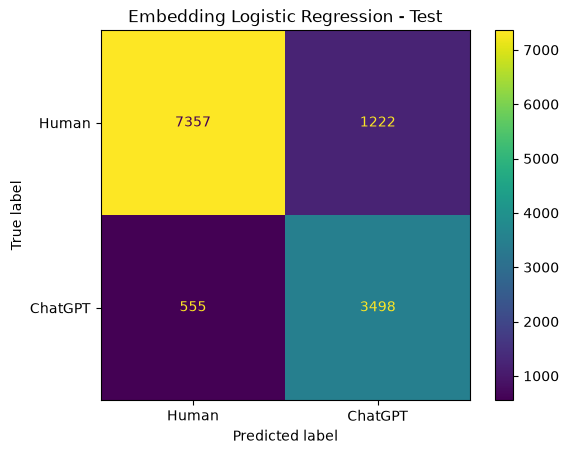

In [11]:
test_cm = confusion_matrix(
    y_test,
    test_preds
)

print("Test Confusion Matrix:")
print(test_cm)

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Human", "ChatGPT"]
).plot()

plt.title(
    "Embedding Logistic Regression - Test"
)

plt.show()

## ROC Curve

Visualize the logistic regression model's ability to distinguish between human and ChatGPT-generated text across classification thresholds.

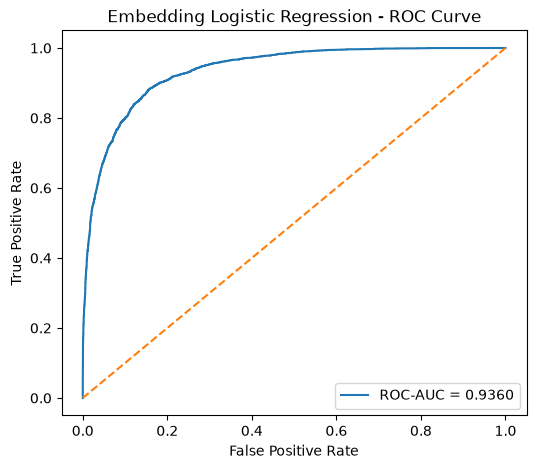

In [13]:
test_probs = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    test_probs
)

test_auc = roc_auc_score(
    y_test,
    test_probs
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {test_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Embedding Logistic Regression - ROC Curve")
plt.legend()
plt.show()

## Save Model

Save the trained embedding-based logistic regression model for reuse and comparison.

In [12]:
import joblib

logistic_model_path = (
    EMBEDDINGS_MODEL_DIR
    / "logistic_regression_embeddings.joblib"
)

joblib.dump(
    model,
    logistic_model_path
)

print("Saved:")
print(logistic_model_path)

Saved:
../../models/embeddings/logistic_regression_embeddings.joblib
